# 05 · How much bf16 loses, and whether the specialists share `A`

Two checks on the existing seed-42 checkpoints. No training, no eval. CPU is enough (~5-10 min).

| Part | Question |
|---|---|
| **1** | Each specialist: how much of its task vector is lost when `merged/` is saved in bf16? Size **and** direction. |
| **2** | Each merge: how much is lost in the merged model on disk, and at which step? |
| **3** | Do the three specialists' final `A` matrices point the same way? Was it the shared random start? |
| **4** | Summary to paste into the log. |

Names used throughout:
- **exact tv** = `s · B @ A` from `adapter/`, in float32. What training actually learned.
- **saved tv** = `merged/ − base`, read from disk. What `merge.py` used.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt, pandas as pd
from safetensors import safe_open
from src.merge.merge import LazyWeights, ties

BASE = "Qwen/Qwen2.5-0.5B-Instruct"     # HF id (read from your HF cache) or a local folder
SEED = 42
TASKS = ["gsm8k", "logic", "code"]
METHODS = ["avg", "task_arithmetic", "ties"]
MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
SPEC = {t: ROOT / f"checkpoints/specialists/{t}/seed{SEED}" for t in TASKS}
MERGED = {m: ROOT / f"checkpoints/merged/{m}" for m in METHODS}
PAIRS = [(0, 1), (0, 2), (1, 2)]

C_TASK = dict(zip(TASKS, ["#2a78d6", "#eb6834", "#1baf7a"]))
C_METHOD = dict(zip(METHODS, ["#eda100", "#e87ba4", "#008300"]))
C_PAIR = ["#6250d6", "#e34948", "#6b6b6b"]
torch.set_printoptions(precision=4, sci_mode=False, linewidth=150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e4e0", "axes.axisbelow": True})

def sub(module):
    return "self_attn" if module in MODULES[:4] else "mlp"

def wname(layer, module):
    return f"model.layers.{layer}.{sub(module)}.{module}.weight"

base = LazyWeights(BASE)
N_LAYERS = json.loads((base.path / "config.json").read_text())["num_hidden_layers"]
specs = {t: LazyWeights(SPEC[t] / "merged") for t in TASKS}
AD = {t: safe_open(SPEC[t] / "adapter" / "adapter_model.safetensors", "pt") for t in TASKS}
ACFG = {t: json.loads((SPEC[t] / "adapter" / "adapter_config.json").read_text()) for t in TASKS}
SCALE = {t: ACFG[t]["lora_alpha"] / ACFG[t]["r"] for t in TASKS}

def AB(t, l, m):
    p = f"base_model.model.model.layers.{l}.{sub(m)}.{m}"
    return AD[t].get_tensor(p + ".lora_A.weight").float(), AD[t].get_tensor(p + ".lora_B.weight").float()

def exact_tv(t, l, m):
    A, B = AB(t, l, m)
    return SCALE[t] * B @ A

KEYS = [(l, m) for l in range(N_LAYERS) for m in MODULES]
cos = lambda dot, n1, n2: dot / np.sqrt(n1 * n2)
print("base:", base.path)
print("adapter dtype:", AD[TASKS[0]].get_tensor(next(iter(AD[TASKS[0]].keys()))).dtype,
      "| scale:", SCALE, "| matrices:", len(KEYS))

/mnt/EAD854DBD854A799/IITB Course/Sem 7/CS769 (Optimisation in Machine Learning)/Project (Does RL-induced reasoning survive merging)/Does_RL-induced_reasoning_survive_merging/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 6 files: 100%|██████████| 6/6 [00:00<00:00, 1233.56it/s]

base: /home/navya-garg/.cache/huggingface/hub/models--Qwen--Qwen2.5-0.5B-Instruct/snapshots/7ae557604adf67be50417f59c2c2f167def9a775
adapter dtype: torch.float32 | scale: {'gsm8k': 2.0, 'logic': 2.0, 'code': 2.0} | matrices: 168


---
# Part 1 · bf16 loss per specialist

For every one of the 168 matrices, compare saved tv with exact tv:

- **size kept** = |saved| / |exact|. 1 = nothing lost.
- **direction kept** = cosine(saved, exact). 1 = same direction.
- **error** = |saved − exact| / |exact|. How big the rounding damage is compared with the update itself.
- **zeroed** = entries where exact ≠ 0 but saved = 0, and the share of the update's size (norm²) that sat in them.

Also: are the task vectors still nearly orthogonal when measured **exactly**? (Notebook 03 used saved ones.)

In [2]:
T = len(TASKS)
G_ex = np.zeros((T, T)); G_sv = np.zeros((T, T))          # <tv_i, tv_j>, exact and saved
X = np.zeros(T)                                            # <saved_t, exact_t>
E2 = np.zeros(T)                                           # |saved_t - exact_t|^2
nz_ex = np.zeros(T); zeroed = np.zeros(T); zeroed_n2 = np.zeros(T); total = 0
COS_LM = np.zeros((T, N_LAYERS, len(MODULES)))             # per-matrix direction kept
RAT_LM = np.zeros((T, N_LAYERS, len(MODULES)))             # per-matrix size kept
BINS = np.arange(-6, 0.01, 0.5)                            # log10 |W| buckets
bin_ex = np.zeros((T, len(BINS) + 1)); bin_kept = np.zeros((T, len(BINS) + 1))

for l, m in KEYS:
    j = MODULES.index(m)
    W = base.get(wname(l, m))
    Wf = W.float()
    ex = torch.stack([exact_tv(t, l, m) for t in TASKS]).flatten(1).double()
    sv = torch.stack([specs[t].get(wname(l, m)).float() - Wf for t in TASKS]).flatten(1).double()
    G_ex += (ex @ ex.T).numpy(); G_sv += (sv @ sv.T).numpy()
    X += (sv * ex).sum(1).numpy()
    E2 += ((sv - ex) ** 2).sum(1).numpy()
    lost = (sv == 0) & (ex != 0)
    nz_ex += (ex != 0).sum(1).numpy(); zeroed += lost.sum(1).numpy()
    zeroed_n2 += ((ex ** 2) * lost).sum(1).numpy()
    total += ex.shape[1]
    d = (sv * ex).sum(1); ns = (sv ** 2).sum(1); ne = (ex ** 2).sum(1)
    COS_LM[:, l, j] = (d / (ns * ne).sqrt()).numpy()
    RAT_LM[:, l, j] = (ns / ne).sqrt().numpy()
    b = np.digitize(np.log10(Wf.abs().flatten().clamp(min=1e-12).numpy()), BINS)
    for i in range(T):
        e2 = (ex[i] ** 2).numpy()
        bin_ex[i] += np.bincount(b, weights=e2, minlength=len(BINS) + 1)
        bin_kept[i] += np.bincount(b, weights=e2 * (sv[i] != 0).numpy(), minlength=len(BINS) + 1)

n_ex, n_sv = np.diag(G_ex), np.diag(G_sv)
rows = []
for i, t in enumerate(TASKS):
    rows.append({"task": t, "|exact|": np.sqrt(n_ex[i]), "|saved|": np.sqrt(n_sv[i]),
                 "size kept": np.sqrt(n_sv[i] / n_ex[i]), "direction kept (cos)": cos(X[i], n_sv[i], n_ex[i]),
                 "error |sv-ex|/|ex|": np.sqrt(E2[i] / n_ex[i]),
                 "entries zeroed": zeroed[i] / nz_ex[i], "update norm² in zeroed": zeroed_n2[i] / n_ex[i]})
P1 = pd.DataFrame(rows).set_index("task")
P1.style.format("{:.3f}").format("{:.1%}", subset=["entries zeroed", "update norm² in zeroed"])

,|exact|,|saved|,size kept,direction kept (cos),error |sv-ex|/|ex|,entries zeroed,update norm² in zeroed
task,,,,,,,
gsm8k,0.771,0.777,1.009,0.845,0.559,60.0%,23.9%
logic,0.750,0.754,1.005,0.842,0.564,60.9%,24.5%
code,0.784,0.792,1.010,0.848,0.554,59.5%,23.3%


Reading it:
- size kept near 1 and cosine near 1 → bf16 lost little, even if many entries were zeroed (the zeroed ones were the small ones).
- cosine well below 1 → the saved task vector points somewhere else. Everything built from `merged/` (notebook 03, the merges) inherits that.
- The error column is the cleanest single number: 0.3 means the rounding damage is 30% the size of the update.

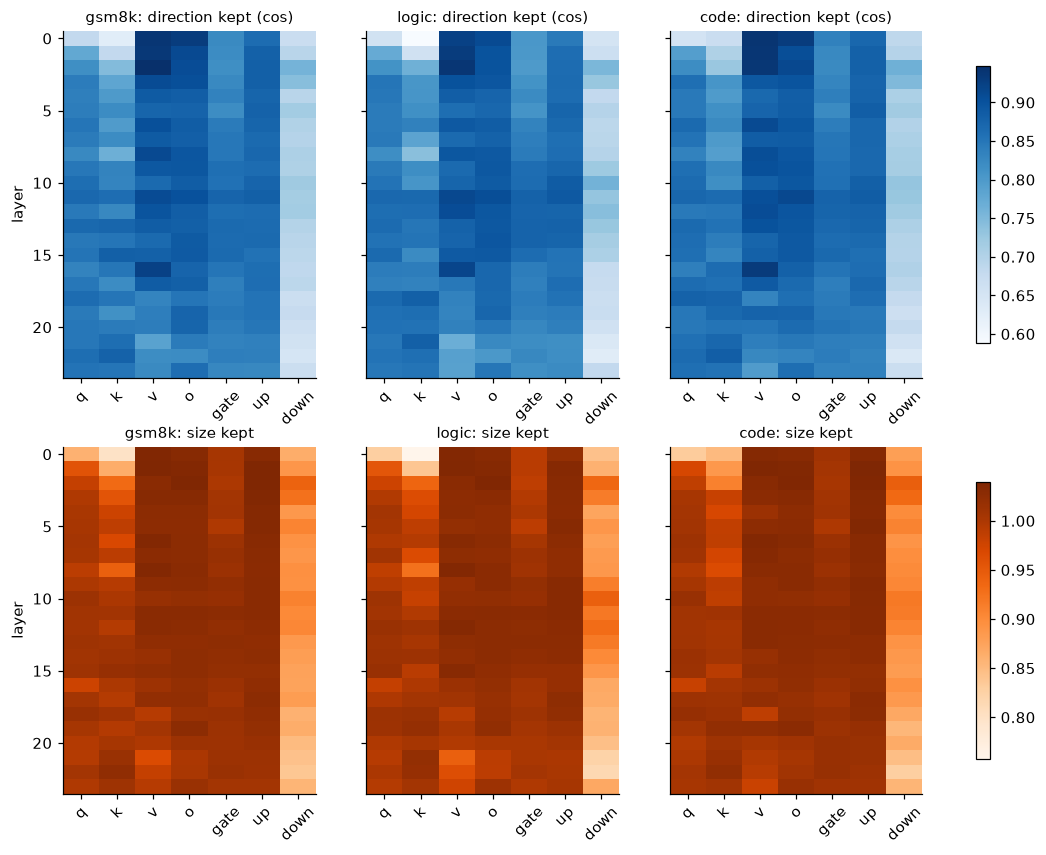

In [3]:
fig, axes = plt.subplots(2, T, figsize=(4.2 * T, 9), sharey=True)
for i, t in enumerate(TASKS):
    for row, (arr, name, cmap, lo) in enumerate([(COS_LM, "direction kept (cos)", "Blues", None),
                                                  (RAT_LM, "size kept", "Oranges", None)]):
        ax = axes[row, i]
        im = ax.imshow(arr[i], cmap=cmap, vmin=arr.min(), vmax=arr.max(), aspect="auto")
        ax.set_xticks(range(len(MODULES)), [m.replace("_proj", "") for m in MODULES], rotation=45)
        ax.set_title(f"{t}: {name}", fontsize=10); ax.grid(False)
        if i == T - 1: fig.colorbar(im, ax=axes[row], shrink=0.8)
axes[0, 0].set_ylabel("layer"); axes[1, 0].set_ylabel("layer")
plt.show()

Where does the loss happen? bf16 steps are **relative** to the weight, so a change on a big weight is more likely to be rounded away.
Bars: share of the update's norm² that survived saving, by size of the base weight. Line: where the update's norm² sits.

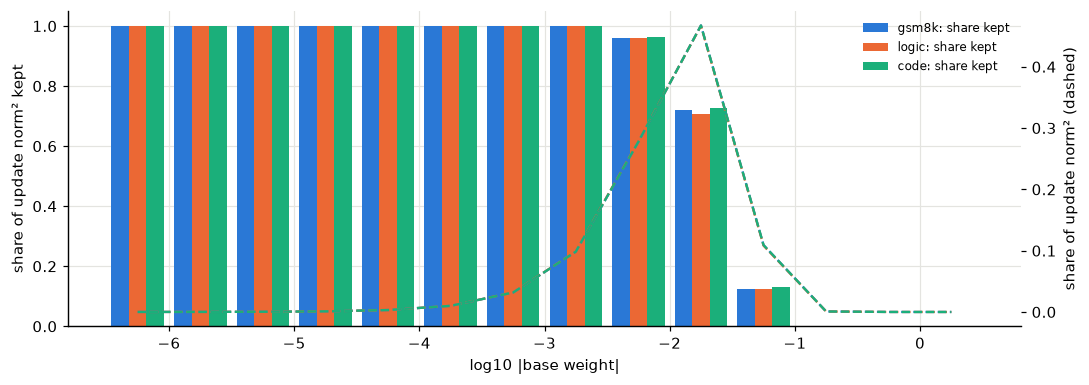

In [4]:
mid = np.concatenate([[BINS[0] - 0.25], BINS + 0.25])
fig, ax = plt.subplots(figsize=(10, 3.6)); ax2 = ax.twinx()
w = 0.14
for i, t in enumerate(TASKS):
    keep = np.divide(bin_kept[i], bin_ex[i], out=np.full_like(bin_ex[i], np.nan), where=bin_ex[i] > 0)
    ax.bar(mid + (i - 1) * w, keep, w, color=C_TASK[t], label=f"{t}: share kept")
    ax2.plot(mid, bin_ex[i] / bin_ex[i].sum(), color=C_TASK[t], lw=1.5, ls="--")
ax.set_xlabel("log10 |base weight|"); ax.set_ylabel("share of update norm² kept"); ax.set_ylim(0, 1.05)
ax2.set_ylabel("share of update norm² (dashed)"); ax2.grid(False)
ax.legend(frameon=False, fontsize=8, loc="upper right"); plt.tight_layout(); plt.show()

### Do the task vectors still look orthogonal when measured exactly?

In [5]:
C_ex = G_ex / np.sqrt(np.outer(n_ex, n_ex)); C_sv = G_sv / np.sqrt(np.outer(n_sv, n_sv))
for i, j in PAIRS:
    print(f"{TASKS[i]:>6} · {TASKS[j]:<6}  cos exact {C_ex[i, j]:.3f}   cos saved {C_sv[i, j]:.3f}")

 gsm8k · logic   cos exact 0.041   cos saved 0.033
 gsm8k · code    cos exact 0.023   cos saved 0.019
 logic · code    cos exact 0.029   cos saved 0.024


---
# Part 2 · bf16 loss in the merged models

Three versions of each merge delta (Δ = merged − base):

| version | built from | rounding |
|---|---|---|
| **exact** | exact tvs, merged in float32 | none |
| **mid** | saved tvs, merged in float32 | specialists' save only |
| **disk** | `checkpoints/merged/<method>/` − base | specialists' save + the merge's own save |

`exact` is what the merge would be with no bf16 at all. Comparing the three shows which save does the damage.
Uses the same λ and TIES density as the real merges (read from `merge_info.json`).

In [6]:
def combine(tvs, method, lam, density):
    if method == "avg":
        return tvs.mean(0)
    if method == "task_arithmetic":
        return lam * tvs.sum(0)
    return lam * ties(tvs, density)

INFO = {m: json.loads((MERGED[m] / "merge_info.json").read_text()) for m in METHODS if (MERGED[m] / "merge_info.json").exists()}
M_ = [m for m in METHODS if m in INFO]
disk = {m: LazyWeights(MERGED[m]) for m in M_}
acc = {m: {k: 0.0 for k in ["ee", "mm", "dd", "me", "de", "dm", "nz_e", "zero_d"]} for m in M_}
share = {m: {v: np.zeros(T) for v in ["exact", "disk"]} for m in M_}

for l, m_ in KEYS:
    W = base.get(wname(l, m_)); Wf = W.float()
    ex = torch.stack([exact_tv(t, l, m_) for t in TASKS])
    sv = torch.stack([specs[t].get(wname(l, m_)).float() - Wf for t in TASKS])
    exd = ex.flatten(1).double()
    for m in M_:
        lam, dens = INFO[m].get("lam", 1.0), INFO[m].get("density", 0.2)
        e = combine(ex, m, lam, dens).double().flatten()
        mi = combine(sv, m, lam, dens).double().flatten()
        d = (disk[m].get(wname(l, m_)).float() - Wf).double().flatten()
        a = acc[m]
        a["ee"] += (e @ e).item(); a["mm"] += (mi @ mi).item(); a["dd"] += (d @ d).item()
        a["me"] += (mi @ e).item(); a["de"] += (d @ e).item(); a["dm"] += (d @ mi).item()
        a["nz_e"] += (e != 0).sum().item(); a["zero_d"] += ((d == 0) & (e != 0)).sum().item()
        share[m]["exact"] += (exd @ e).numpy(); share[m]["disk"] += (exd @ d).numpy()

rows = []
for m in M_:
    a = acc[m]
    rows.append({"method": m, "|exact Δ|": np.sqrt(a["ee"]), "|disk Δ|": np.sqrt(a["dd"]),
                 "size kept (disk)": np.sqrt(a["dd"] / a["ee"]), "cos(disk, exact)": cos(a["de"], a["dd"], a["ee"]),
                 "cos(mid, exact)": cos(a["me"], a["mm"], a["ee"]), "cos(disk, mid)": cos(a["dm"], a["dd"], a["mm"]),
                 "exact entries zeroed on disk": a["zero_d"] / a["nz_e"]})
P2 = pd.DataFrame(rows).set_index("method")
P2.style.format("{:.3f}").format("{:.1%}", subset=["exact entries zeroed on disk"])

,|exact Δ|,|disk Δ|,size kept (disk),"cos(disk, exact)","cos(mid, exact)","cos(disk, mid)",exact entries zeroed on disk
method,,,,,,,
avg,0.457,0.453,0.992,0.719,0.850,0.808,71.8%
task_arithmetic,1.371,1.375,1.003,0.850,0.850,1.000,46.3%
ties,0.985,1.064,1.081,0.799,0.801,0.998,30.3%


- `cos(mid, exact)` low → the specialists' save did the damage.
- `cos(disk, mid)` low → the merge's own save did more damage on top (expected for avg: it divides by 3, then rounds again).

### Share of each specialist carried by each merge, measured with exact task vectors

share_t = ⟨Δ, exact tv_t⟩ / |exact tv_t|². Notebook 03 got 0.28 (avg), 1.05 (task arithmetic), 0.72 (TIES) using saved vectors.

In [7]:
rows = []
for m in M_:
    for v in ["exact", "disk"]:
        rows.append({"method": m, "Δ version": v, **{t: share[m][v][i] / n_ex[i] for i, t in enumerate(TASKS)}})
P2s = pd.DataFrame(rows).set_index(["method", "Δ version"])
P2s.style.format("{:.3f}")

---
# Part 3 · Do the specialists share `A`?

LoRA: ΔW = s · B @ A. `A` starts **random**, `B` starts at **0**.
All three specialists ran with seed 42, so if nothing else drew random numbers first, they started from the **same** `A`.

- cos(A_t, A_u) ≈ 1 → same start, and `A` barely moved.
- cos(A_t, A_u) ≈ 0 → different starts. Two random 16 × 896 matrices have cosine ≈ ±0.01.
- `B` started at 0, so cos(B_t, B_u) is overlap the tasks **learned**. It is the honest version of the overlap in notebook 03.

In [8]:
cA = np.zeros((len(PAIRS), N_LAYERS, len(MODULES))); cB = np.zeros_like(cA)
gA = np.zeros((T, T)); gB = np.zeros((T, T))
for l, m in KEYS:
    j = MODULES.index(m)
    ab = [AB(t, l, m) for t in TASKS]
    A = torch.stack([x[0].flatten() for x in ab]).double(); B = torch.stack([x[1].flatten() for x in ab]).double()
    ga, gb = (A @ A.T).numpy(), (B @ B.T).numpy()
    gA += ga; gB += gb
    for p, (i, k) in enumerate(PAIRS):
        cA[p, l, j] = cos(ga[i, k], ga[i, i], ga[k, k]); cB[p, l, j] = cos(gb[i, k], gb[i, i], gb[k, k])

rows = []
for p, (i, k) in enumerate(PAIRS):
    rows.append({"pair": f"{TASKS[i]} · {TASKS[k]}", "cos A (all)": cos(gA[i, k], gA[i, i], gA[k, k]),
                 "cos A (min matrix)": cA[p].min(), "cos B (all)": cos(gB[i, k], gB[i, i], gB[k, k]),
                 "cos ΔW exact": C_ex[i, k]})
P3 = pd.DataFrame(rows).set_index("pair")
P3.style.format("{:.3f}")

,cos A (all),cos A (min matrix),cos B (all),cos ΔW exact
pair,,,,
gsm8k · logic,0.999,0.997,0.041,0.041
gsm8k · code,0.999,0.997,0.023,0.023
logic · code,0.999,0.997,0.030,0.029


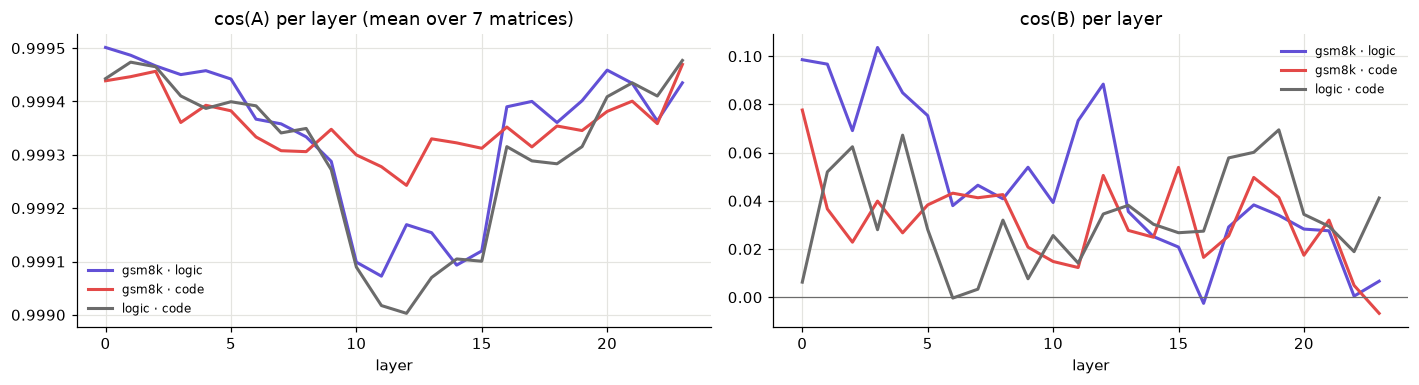

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for p, (i, k) in enumerate(PAIRS):
    lab = f"{TASKS[i]} · {TASKS[k]}"
    axes[0].plot(range(N_LAYERS), cA[p].mean(1), color=C_PAIR[p], lw=2, label=lab)
    axes[1].plot(range(N_LAYERS), cB[p].mean(1), color=C_PAIR[p], lw=2, label=lab)
axes[0].set_title("cos(A) per layer (mean over 7 matrices)"); axes[1].set_title("cos(B) per layer")
for ax in axes: ax.set_xlabel("layer"); ax.legend(frameon=False, fontsize=8)
axes[1].axhline(0, color="#6b6b6b", lw=0.8)
plt.tight_layout(); plt.show()

### Rebuild the starting `A` and measure how far it moved

`grpo.py` calls `set_seed(seed)`, loads the model, and TRL wraps it in LoRA. Repeat that here on CPU.
If the rebuilt `A` matches the trained ones closely (cosine near 1), it **is** the starting point, and
|A_final − A_init| / |A_init| says how far training moved `A`.
If cosine is near 0, something else drew random numbers first; then this cell tells nothing, and the pairwise cosines above are the evidence.

In [10]:
from peft import LoraConfig, get_peft_model
from transformers import AutoModelForCausalLM
from src.utils.seed import set_seed

c = ACFG[TASKS[0]]
set_seed(SEED)
m0 = AutoModelForCausalLM.from_pretrained(str(base.path), dtype=torch.bfloat16)
m0 = get_peft_model(m0, LoraConfig(task_type="CAUSAL_LM", r=c["r"], lora_alpha=c["lora_alpha"],
                                   lora_dropout=c["lora_dropout"], target_modules=c["target_modules"]))
A0 = {}
for name, p in m0.named_parameters():
    if "lora_A" in name:
        parts = name.split(".")
        l = int(parts[parts.index("layers") + 1]); m = parts[parts.index("layers") + 3]
        A0[(l, m)] = p.detach().float()
del m0

n0 = 0.0; dot = np.zeros(T); nf = np.zeros(T); moved = np.zeros(T)
for l, m in KEYS:
    a0 = A0[(l, m)].double().flatten(); n0 += (a0 @ a0).item()
    for i, t in enumerate(TASKS):
        a = AB(t, l, m)[0].double().flatten()
        dot[i] += (a @ a0).item(); nf[i] += (a @ a).item(); moved[i] += ((a - a0) ** 2).sum().item()
P3b = pd.DataFrame({"cos(A_final, A_init)": dot / np.sqrt(nf * n0),
                    "|A_final − A_init| / |A_init|": np.sqrt(moved / n0)}, index=TASKS)
P3b.style.format("{:.4f}")

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 6738.77it/s]


,"cos(A_final, A_init)",|A_final − A_init| / |A_init|
gsm8k,0.9996,0.0268
logic,0.9996,0.0280
code,0.9996,0.0269


---
# Part 4 · Summary

Prints the key numbers in one block. Paste it back to me.

In [11]:
print("PART 1  specialist tvs: exact (adapter, fp32) vs saved (merged/ - base)")
print(P1.to_string(float_format=lambda v: f"{v:.3f}"))
print("cos between tasks, exact vs saved:", ", ".join(f"{TASKS[i]}·{TASKS[j]} {C_ex[i, j]:.3f}/{C_sv[i, j]:.3f}" for i, j in PAIRS))
print("\nPART 2  merge deltas")
print(P2.to_string(float_format=lambda v: f"{v:.3f}"))
print(P2s.to_string(float_format=lambda v: f"{v:.3f}"))
print("\nPART 3  A and B overlap")
print(P3.to_string(float_format=lambda v: f"{v:.3f}"))
print(P3b.to_string(float_format=lambda v: f"{v:.4f}"))

PART 1  specialist tvs: exact (adapter, fp32) vs saved (merged/ - base)
       |exact|  |saved|  size kept  direction kept (cos)  error |sv-ex|/|ex|  entries zeroed  update norm² in zeroed
task                                                                                                                
gsm8k    0.771    0.777      1.009                 0.845               0.559           0.600                   0.239
logic    0.750    0.754      1.005                 0.842               0.564           0.609                   0.245
code     0.784    0.792      1.010                 0.848               0.554           0.595                   0.233
cos between tasks, exact vs saved: gsm8k·logic 0.041/0.033, gsm8k·code 0.023/0.019, logic·code 0.029/0.024

PART 2  merge deltas
                 |exact Δ|  |disk Δ|  size kept (disk)  cos(disk, exact)  cos(mid, exact)  cos(disk, mid)  exact entries zeroed on disk
method                                                                        